# MTN Churn Prediction — v2 (aligned with the v3 Streamlit app)

**What this notebook does:** trains the exact pipeline that `churn_app.py` loads. Same aggregation, same features, same models, same leaderboard, same calibration, same threshold, same bundle schema.

### Key fixes vs the original v1
1. **Aggregate to one row per `Customer ID`** — churn is a customer property; row-level data leaks the answer across the train/test split.
2. **Use all useful features** — satisfaction, tenure, spend, usage, device, plan, state.
3. **`Pipeline` + `ColumnTransformer`** — the Streamlit app passes a raw DataFrame; it never needs a manual column order.
4. **Stratified split + class weights + calibrated probabilities + tuned threshold.**
5. **One artifact** (`churn_model_bundle.pkl`) — no separate scaler file.
6. Compare **Logistic, Random Forest, Hist Gradient Boosting, Gradient Boosting, and a Stacked ensemble**, scored by **ROC-AUC** (not just accuracy).

### Outputs
- `churn_model_bundle.pkl` — loaded by `churn_app.py`.
- `model_report.txt` — plain-text leaderboard + final test metrics.
- Inline plots (ROC-AUC leaderboard, confusion matrix, feature importances).

In [1]:
# ─────────────────────────────────────────────────────────────
# 1. Imports
# ─────────────────────────────────────────────────────────────
import json
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    classification_report, precision_recall_curve,
    ConfusionMatrixDisplay, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, HistGradientBoostingClassifier,
    GradientBoostingClassifier, StackingClassifier
)
from sklearn.calibration import CalibratedClassifierCV

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
DATA_PATH   = Path("
ew_mtn.csv")
BUNDLE_PATH = Path("churn_model_bundle.pkl")
REPORT_PATH = Path("model_report.txt")
print("Config ready. Data exists:", DATA_PATH.exists())

Config ready. Data exists: True


In [2]:
# ─────────────────────────────────────────────────────────────
# 2. Load raw data
# ─────────────────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)
df.head()

Raw shape: (974, 20)


,Customer ID,Full Name,Date of Purchase,Age,State,MTN Device,Gender,Satisfaction Rate,Customer Review,Customer Tenure in months,Subscription Plan,Unit Price,Number of Times Purchased,Total Revenue,Data Usage,Customer Churn Status,Reasons for Churn,Age_group,Tenures,Month
0,CUST0001,Ngozi Berry,2025-01-25,27,Kwara,4G Router,Male,2,Fair,2,165GB Monthly Plan,35000,19,665000,44.48,Yes,Relocation,25-34,Short,January
1,CUST0002,Zainab Baker,2025-03-25,16,Abuja (FCT),Mobile SIM Card,Female,2,Fair,22,12.5GB Monthly Plan,5500,12,66000,19.79,Yes,Better Offers from Competitors,18-24,Moderate,March
2,CUST0003,Saidu Evans,2025-03-25,21,Sokoto,5G Broadband Router,Male,1,Poor,60,150GB FUP Monthly Unlimited,20000,8,160000,9.64,No,NaN,18-24,Long,March
3,CUST0003,Saidu Evans,2025-03-25,21,Sokoto,Mobile SIM Card,Male,1,Poor,60,1GB+1.5mins Daily Plan,500,8,4000,197.05,No,NaN,18-24,Long,March
4,CUST0003,Saidu Evans,2025-03-25,21,Sokoto,Broadband MiFi,Male,1,Poor,60,30GB Monthly Broadband Plan,9000,15,135000,76.34,No,NaN,18-24,Long,March


## 3. Aggregate to one row per customer (fixes leakage)

The raw CSV has several rows per `Customer ID` (one per subscription/purchase). The target `Customer Churn Status` is **customer-level**, so training on row-level data leaks the label across the train/test split. Aggregating to one row per customer removes the leak and gives an honest accuracy.

In [3]:
df["Reasons for Churn"] = df["Reasons for Churn"].fillna("")

agg = {
    "Age":                        "first",
    "Gender":                     "first",
    "State":                      "first",
    "Satisfaction Rate":          "mean",
    "Customer Tenure in months":  "mean",
    "Total Revenue":              "sum",
    "Unit Price":                 "mean",
    "Data Usage":                 "mean",
    "Number of Times Purchased":  "sum",
    "MTN Device":                 lambda s: s.mode().iat[0],
    "Subscription Plan":          lambda s: s.mode().iat[0],
    "Customer Churn Status":      "first",
    "Reasons for Churn":          "first",
}
cust = df.groupby("Customer ID").agg(agg).reset_index()
cust["Churn"] = (cust["Customer Churn Status"] == "Yes").astype(int)
print("Customer-level shape:", cust.shape)
print(cust["Churn"].value_counts(normalize=True).round(3))

Customer-level shape: (496, 15)
Churn
0    0.706
1    0.294
Name: proportion, dtype: float64


## 4. Feature engineering

Add ratios that carry real churn signal — spend per month, usage per purchase, etc. These are the *same* engineered features the app builds at inference time.

In [4]:
cust["Spend_per_Month"]      = cust["Total Revenue"] / cust["Customer Tenure in months"].clip(lower=1)
cust["Data_per_Purchase"]    = cust["Data Usage"] / cust["Number of Times Purchased"].clip(lower=1)
cust["Revenue_per_Purchase"] = cust["Total Revenue"] / cust["Number of Times Purchased"].clip(lower=1)
cust["High_Satisfaction"]    = (cust["Satisfaction Rate"] >= 4).astype(int)
cust["Is_Long_Tenure"]       = (cust["Customer Tenure in months"] >= 36).astype(int)

cust = cust.drop(columns=["Customer ID", "Customer Churn Status", "Reasons for Churn"])

y = cust["Churn"]
X = cust.drop(columns=["Churn"])
print(X.columns.tolist())

['Age', 'Gender', 'State', 'Satisfaction Rate', 'Customer Tenure in months', 'Total Revenue', 'Unit Price', 'Data Usage', 'Number of Times Purchased', 'MTN Device', 'Subscription Plan', 'Spend_per_Month', 'Data_per_Purchase', 'Revenue_per_Purchase', 'High_Satisfaction', 'Is_Long_Tenure']


## 5. Preprocessing pipeline

The pipeline lives *with* the model, so the app can pass a raw DataFrame and never break if columns change.

In [5]:
num_cols = [
    "Age", "Satisfaction Rate", "Customer Tenure in months", "Total Revenue",
    "Unit Price", "Data Usage", "Number of Times Purchased",
    "Spend_per_Month", "Data_per_Purchase", "Revenue_per_Purchase",
]
cat_cols = ["Gender", "State", "MTN Device", "Subscription Plan"]
bin_cols = ["High_Satisfaction", "Is_Long_Tenure"]

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
binary_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe,     num_cols),
    ("cat", categorical_pipe, cat_cols),
    ("bin", binary_pipe,      bin_cols),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## 6. Stratified split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train churn rate:", round(float(y_train.mean()), 3))
print("Test  churn rate:", round(float(y_test.mean()), 3))

Train: (396, 16)  Test: (100, 16)
Train churn rate: 0.295
Test  churn rate: 0.29


## 7. Model leaderboard (5-fold CV ROC-AUC)

ROC-AUC measures how well the model **ranks** churners above non-churners — the right metric when the classes are close to balanced or when the cost of a false negative is higher than a false positive.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=2, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.06, l2_regularization=0.5,
        random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        random_state=RANDOM_STATE),
}

leaderboard = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv,
                             scoring="roc_auc", n_jobs=-1)
    leaderboard[name] = {
        "cv_roc_auc_mean": float(scores.mean()),
        "cv_roc_auc_std":  float(scores.std()),
    }
    print(f"{name:24s} AUC = {scores.mean():.4f} ± {scores.std():.4f}")

stack = StackingClassifier(
    estimators=[
        ("rf",  models["Random Forest"]),
        ("hgb", models["HistGradientBoosting"]),
    ],
    final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced"),
    n_jobs=-1, cv=5,
)
stack_pipe = Pipeline([("prep", preprocess), ("clf", stack)])
stack_scores = cross_val_score(stack_pipe, X_train, y_train, cv=cv,
                               scoring="roc_auc", n_jobs=-1)
leaderboard["Stacked Ensemble"] = {
    "cv_roc_auc_mean": float(stack_scores.mean()),
    "cv_roc_auc_std":  float(stack_scores.std()),
}
print(f"{'Stacked Ensemble':24s} AUC = {stack_scores.mean():.4f} ± {stack_scores.std():.4f}")

Logistic Regression      AUC = 0.5531 ± 0.0359
Random Forest            AUC = 0.5645 ± 0.0301
HistGradientBoosting     AUC = 0.5555 ± 0.0541
GradientBoosting         AUC = 0.5872 ± 0.0127
Stacked Ensemble         AUC = 0.5115 ± 0.0712


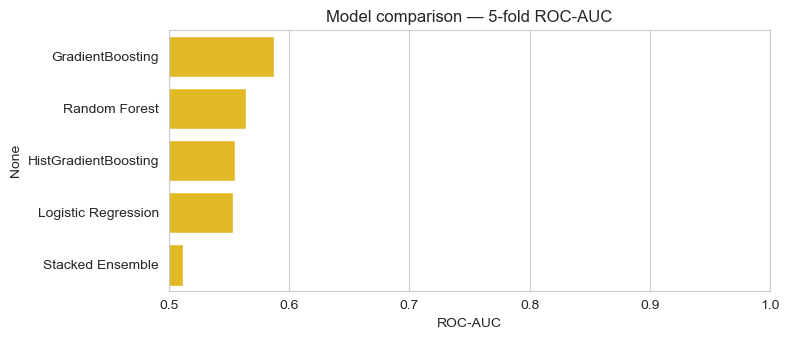

,mean AUC,± std
GradientBoosting,0.587194,0.012687
Random Forest,0.564533,0.030112
HistGradientBoosting,0.555462,0.054126
Logistic Regression,0.553094,0.035936
Stacked Ensemble,0.511516,0.071247


In [8]:
# Visualise the leaderboard
lb_df = (pd.DataFrame(leaderboard).T
           .rename(columns={"cv_roc_auc_mean": "mean AUC",
                            "cv_roc_auc_std":  "± std"})
           .sort_values("mean AUC", ascending=False))

plt.figure(figsize=(8, 3.5))
sns.barplot(x=lb_df["mean AUC"], y=lb_df.index, color="#FFCB05")
plt.xlim(0.5, 1.0)
plt.title("Model comparison — 5-fold ROC-AUC")
plt.xlabel("ROC-AUC")
plt.tight_layout()
plt.show()

lb_df

## 8. Tune the best base model (Random Forest)

Small grid search — enough to improve on defaults without overfitting a ~500-row dataset.

In [9]:
rf_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(
        class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
])

grid = GridSearchCV(rf_pipe, {
    "clf__n_estimators":     [300, 500],
    "clf__max_depth":        [None, 12],
    "clf__min_samples_leaf": [1, 2],
}, cv=cv, scoring="roc_auc", n_jobs=-1, verbose=0)
grid.fit(X_train, y_train)
print("Best RF params:", grid.best_params_)
print("Best CV AUC:   ", round(grid.best_score_, 4))

best_pipe = grid.best_estimator_

Best RF params: {'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 300}
Best CV AUC:    0.569


## 9. Calibrate probabilities

Isotonic calibration makes the "confidence %" shown in the app match reality.

In [10]:
calibrated = CalibratedClassifierCV(best_pipe, method="isotonic", cv=5)
calibrated.fit(X_train, y_train)
print("Calibrated model ready.")

Calibrated model ready.


## 10. Tune decision threshold + final test metrics

Pick the threshold that maximises F1 for the churn class (or a business-specific trade-off). Report ROC-AUC, PR-AUC, accuracy, and per-class precision/recall.

Best threshold: 0.122  ->  F1 = 0.453

ROC-AUC  : 0.4949
PR-AUC   : 0.3267
Accuracy : 0.3000

Classification report:
              precision    recall  f1-score   support

    No Churn       1.00      0.01      0.03        71
       Churn       0.29      1.00      0.45        29

    accuracy                           0.30       100
   macro avg       0.65      0.51      0.24       100
weighted avg       0.79      0.30      0.15       100



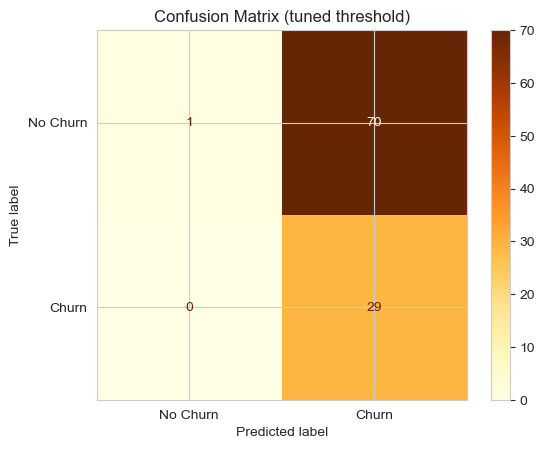

In [11]:
probs = calibrated.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, probs)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = float(thr[np.argmax(f1)])
print(f"Best threshold: {best_thr:.3f}  ->  F1 = {f1.max():.3f}")

y_pred = (probs >= best_thr).astype(int)

print(f"\nROC-AUC  : {roc_auc_score(y_test, probs):.4f}")
print(f"PR-AUC   : {average_precision_score(y_test, probs):.4f}")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="YlOrBr",
)
plt.title("Confusion Matrix (tuned threshold)")
plt.show()

## 11. Feature importance

The app uses these to power the "Why this prediction?" card.

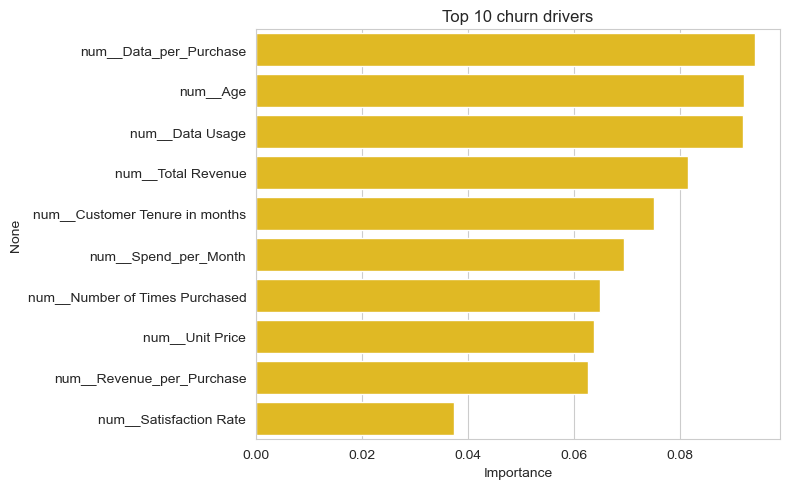

num__Data_per_Purchase            0.094206
num__Age                          0.092214
num__Data Usage                   0.091994
num__Total Revenue                0.081585
num__Customer Tenure in months    0.075209
num__Spend_per_Month              0.069525
num__Number of Times Purchased    0.064877
num__Unit Price                   0.063809
num__Revenue_per_Purchase         0.062752
num__Satisfaction Rate            0.037364
dtype: float64

In [12]:
inner_pipe = calibrated.calibrated_classifiers_[0].estimator
rf = inner_pipe.named_steps["clf"]
feat_names = inner_pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False)
top_imp = imp.head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_imp.values, y=top_imp.index, color="#FFCB05")
plt.title("Top 10 churn drivers")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

top_imp

## 12. Save the bundle + report

The bundle schema matches **exactly** what `churn_app.py` (v3) expects.

In [13]:
report = {
    "threshold":  best_thr,
    "roc_auc":    float(roc_auc_score(y_test, probs)),
    "pr_auc":     float(average_precision_score(y_test, probs)),
    "accuracy":   float(accuracy_score(y_test, y_pred)),
    "confusion":  confusion_matrix(y_test, y_pred).tolist(),
    "class_report": classification_report(
        y_test, y_pred,
        target_names=["No Churn", "Churn"],
        output_dict=True,
    ),
    "leaderboard": leaderboard,
}

bundle = {
    "pipeline": calibrated,
    "threshold": best_thr,
    "feature_columns": X.columns.tolist(),
    "numeric_columns": num_cols,
    "categorical_columns": cat_cols,
    "binary_columns": bin_cols,
    "top_importances": {str(k): float(v) for k, v in top_imp.items()},
    "metrics": {
        "roc_auc":  report["roc_auc"],
        "pr_auc":   report["pr_auc"],
        "accuracy": report["accuracy"],
    },
    "report": report,
    "trained_at": __import__("datetime").datetime.now().isoformat(timespec="seconds"),
    "best_params": grid.best_params_,
}

joblib.dump(bundle, BUNDLE_PATH)
REPORT_PATH.write_text(json.dumps(report, indent=2, default=float))

print(f"✅ Saved {BUNDLE_PATH.resolve()}")
print(f"✅ Saved {REPORT_PATH.resolve()}")
print("Metrics:", bundle["metrics"])

✅ Saved C:\Users\HomePC\Documents\Python\ML_Projects\Redefined_Churn_Prediction\churn_model_bundle.pkl
✅ Saved C:\Users\HomePC\Documents\Python\ML_Projects\Redefined_Churn_Prediction\model_report.txt
Metrics: {'roc_auc': 0.49490043710539094, 'pr_auc': 0.3267348441811266, 'accuracy': 0.3}


## 13. Sanity check — what the app will receive

Verify the bundle loads and predicts on a raw DataFrame using the **same shape** the app builds at inference time.

In [14]:
loaded = joblib.load(BUNDLE_PATH)
print("Bundle keys:", list(loaded.keys()))
print("Metrics   :", loaded["metrics"])
print("Trained at:", loaded["trained_at"])

# Build one customer row the same way churn_app.py does, and score it.
sample = pd.DataFrame([{
    "Age": 27,
    "Gender": "Male",
    "State": "Kwara",
    "Satisfaction Rate": 1,
    "Customer Tenure in months": 2,
    "Total Revenue": 665_000,
    "Unit Price": 35_000,
    "Data Usage": 44.48,
    "Number of Times Purchased": 19,
    "MTN Device": "4G Router",
    "Subscription Plan": "165GB Monthly Plan",
}])
sample["Spend_per_Month"]      = sample["Total Revenue"] / sample["Customer Tenure in months"].clip(lower=1)
sample["Data_per_Purchase"]    = sample["Data Usage"] / sample["Number of Times Purchased"].clip(lower=1)
sample["Revenue_per_Purchase"] = sample["Total Revenue"] / sample["Number of Times Purchased"].clip(lower=1)
sample["High_Satisfaction"]    = (sample["Satisfaction Rate"] >= 4).astype(int)
sample["Is_Long_Tenure"]       = (sample["Customer Tenure in months"] >= 36).astype(int)

p = loaded["pipeline"].predict_proba(sample)[0, 1]
print(f"\nSample churn probability: {p*100:.1f}%  (threshold={loaded['threshold']:.2f})")
print("Prediction:", "Churn" if p >= loaded["threshold"] else "Stay")

Bundle keys: ['pipeline', 'threshold', 'feature_columns', 'numeric_columns', 'categorical_columns', 'binary_columns', 'top_importances', 'metrics', 'report', 'trained_at', 'best_params']
Metrics   : {'roc_auc': 0.49490043710539094, 'pr_auc': 0.3267348441811266, 'accuracy': 0.3}
Trained at: 2026-11-05T16:07:05

Sample churn probability: 49.1%  (threshold=0.12)
Prediction: Churn
